# 25 · Clustering and topic modeling: what are users actually asking?

Production LLM systems generate piles of unlabeled text: user messages, support tickets, failed agent runs, search queries, feedback comments. Before you can evaluate, route or improve anything, you need to know **what is in there**. Clustering and topic modeling answer that without labels. Teams use them to:
- build representative evaluation sets;
- discover intents a router should handle;
- find the questions a RAG system fails on;
- spot **new** topics as they appear.

This notebook runs the modern pipeline (popularized by BERTopic) step by step on **Banking77**: 3,080 real customer messages to a bank. We treat them as unlabeled logs, and use their 77 intent labels only to *measure* how well each step recovers the true structure.

| step | here | measured |
|---|---|---|
| embed | two sentence-embedding models (notebook 21) | which space clusters better |
| choose the number of clusters | k-means with silhouette, no labels | can k be found without labels? |
| reduce + cluster | UMAP + HDBSCAN | clusters found without giving k, noise, effect of UMAP |
| describe | c-TF-IDF keywords + an LLM that names each cluster | do the names match the real intents? |
| monitor | flag messages far from known intents and cluster them | are unseen intents discovered? |

Read it **after notebook 21**, which explains the embeddings everything here is built on.

**Sources.** Alammar and Grootendorst, *Hands-On Large Language Models*, ch. 5 (text clustering and topic modeling); Huyen, *AI Engineering*, ch. 4 and 10 (evaluation data and user feedback).

## Background: grouping texts without labels

### Clustering algorithms, in three families

- **Centroid-based: k-means.** Choose $k$, place $k$ centroids, assign each point to the nearest, move each centroid to the mean of its points, repeat. It is fast and simple. It needs $k$ in advance, assumes round clusters of similar size, and assigns every point, outliers included.
- **Hierarchical (agglomerative).** Start with every point alone and merge the closest pair repeatedly. The result is a tree you can cut at any level. It costs $O(n^2)$ memory, which limits it to tens of thousands of points.
- **Density-based: DBSCAN and HDBSCAN** (Campello et al., 2013). Clusters are dense regions separated by sparse ones. HDBSCAN builds a hierarchy over all density levels and keeps the most stable clusters. It **finds the number of clusters itself**, allows clusters of different shapes and sizes, and labels points in sparse regions as **noise** instead of forcing them into a cluster. Its main knob is `min_cluster_size`.

### Why reduce dimensions first

Embeddings have 384–1,024 dimensions. In high dimensions distances concentrate (the *curse of dimensionality*): the nearest and farthest neighbours of a point end up at similar distances, and density estimates become unreliable. **UMAP** (McInnes et al., 2018) builds a graph of each point's nearest neighbours and finds a low-dimensional layout that preserves that graph, keeping local neighbourhoods while discarding most of the noise in the other directions. Reducing to about 5 dimensions before clustering is the standard trick. 2 dimensions are for plots only, because too much structure is lost.

### Describing clusters: c-TF-IDF and LLMs

A cluster is only useful once a person can tell what it is about. **c-TF-IDF** (class-based TF-IDF, from BERTopic; Grootendorst, 2022) treats all documents of a cluster as one long document and ranks words that are frequent in that cluster but rare across clusters. An **LLM** can then turn those keywords and a few example messages into a readable name ("card arrived damaged"). This is the step that made topic modeling practical, replacing the word lists of LDA, the older probabilistic topic model (Blei et al., 2003).

### Evaluating clusters

- **With labels** (here, for teaching): the **adjusted Rand index** (ARI) compares every pair of points: same cluster vs same label, corrected for chance, so 0 means random and 1 means perfect. **Normalized mutual information** (NMI) measures how much the clustering tells you about the labels.
- **Without labels** (the real situation): the **silhouette score** compares each point's distance to its own cluster with its distance to the nearest other cluster. And in practice, a person reads a sample of every cluster.

### Key papers

- MacQueen (1967), k-means; Arthur & Vassilvitskii (2007), *k-means++: The Advantages of Careful Seeding*.
- Campello, Moulavi & Sander (2013), *Density-Based Clustering Based on Hierarchical Density Estimates* (HDBSCAN).
- McInnes, Healy & Melville (2018), *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction*.
- Blei, Ng & Jordan (2003), *Latent Dirichlet Allocation*.
- Grootendorst (2022), *BERTopic: Neural topic modeling with a class-based TF-IDF procedure*.
- Casanueva et al. (2020), *Efficient Intent Detection with Dual Sentence Encoders* (Banking77).

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-25-clustering")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : off (add LANGSMITH_API_KEY to .env to enable)


In [2]:
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import re, datasets, umap
from collections import Counter
from datasets import load_dataset
from huggingface_hub.utils import logging as hf_logging; hf_logging.set_verbosity_error()
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.feature_extraction.text import CountVectorizer
datasets.disable_progress_bars()
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

bank = load_dataset("PolyAI/banking77")
texts, y = bank["test"]["text"], np.array(bank["test"]["label"])
INTENTS = [n.replace("_", " ") for n in bank["test"].features["label"].names]
print(f"{len(texts)} messages, {len(INTENTS)} intents (used only for evaluation) | e.g.")
for i in [0, 500, 1500]:
    print(f"   {texts[i]!r}  ->  {INTENTS[y[i]]}")
sizes = np.bincount(y)
print(f"messages per intent: min {sizes.min()}, median {int(np.median(sizes))}, max {sizes.max()}")

def score(labels, mask=None):
    m = np.ones(len(y), bool) if mask is None else mask
    return adjusted_rand_score(y[m], labels[m]), normalized_mutual_info_score(y[m], labels[m])

3080 messages, 77 intents (used only for evaluation) | e.g.
   'How do I locate my card?'  ->  card arrival
   'Can my 19 year old daughter open a savings account at the bank?'  ->  age limit
   'I found a charge for a direct debit that was not made by me.'  ->  direct debit payment not recognised
messages per intent: min 40, median 40, max 40


## 1. Embeddings, and k-means when you know k

Two small embedding models from notebook 21: all-MiniLM-L6-v2 and bge-small-en-v1.5. First the easy case: we give k-means the true number of intents, $k = 77$, and cluster the raw embeddings and a 5-dimensional UMAP of them.

In [3]:
EMB, UMAP5 = {}, {}
for name in ["sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5"]:
    short = name.split("/")[1]
    t0 = time.time(); EMB[short] = SentenceTransformer(name, device=device).encode(texts, batch_size=128, normalize_embeddings=True); te = time.time() - t0
    t0 = time.time(); UMAP5[short] = umap.UMAP(n_components=5, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=0).fit_transform(EMB[short]); tu = time.time() - t0
    for space, X in [("raw", EMB[short]), ("UMAP 5-d", UMAP5[short])]:
        a, n = score(KMeans(77, n_init=4, random_state=0).fit_predict(X))
        print(f"{short:18s} k-means k=77 on {space:9s} ARI {a:.3f} | NMI {n:.3f}")
    print(f"{'':18s} encode {te:.1f}s | UMAP {tu:.1f}s")
BEST = "bge-small-en-v1.5"

all-MiniLM-L6-v2   k-means k=77 on raw       ARI 0.504 | NMI 0.794
all-MiniLM-L6-v2   k-means k=77 on UMAP 5-d  ARI 0.576 | NMI 0.831
                   encode 1.9s | UMAP 16.6s


bge-small-en-v1.5  k-means k=77 on raw       ARI 0.581 | NMI 0.834
bge-small-en-v1.5  k-means k=77 on UMAP 5-d  ARI 0.685 | NMI 0.873
                   encode 2.2s | UMAP 5.1s


**What the numbers say.**

| embedding | k-means on raw vectors (ARI / NMI) | k-means on UMAP 5-d (ARI / NMI) |
|---|---|---|
| all-MiniLM-L6-v2 | 0.504 / 0.794 | 0.576 / 0.831 |
| bge-small-en-v1.5 | 0.581 / 0.834 | **0.685 / 0.873** |

- **The embedding space decides most of the quality.** bge-small, which also retrieved better in notebook 21, clusters better on both representations. An embedding model that separates meanings well for search also separates them well for clustering.
- **UMAP helps k-means a lot**, by +0.07 to +0.10 ARI, even though it throws away all but 5 of 384 dimensions. It keeps each message's neighbourhood and drops the directions that only add noise to distances.
- An ARI of 0.685 is far from perfect, even with the right $k$. Several Banking77 intents are genuinely close: "pending transfer" vs "transfer timing", "card arrival" vs "card delivery estimate". No clustering of these sentences can separate what their embeddings place together.

## 2. Choosing k without labels

In real logs nobody tells you $k$. The textbook answer is to try several values and keep the one with the best **silhouette score**. Does it find 77?

k= 10: silhouette 0.475 | ARI 0.106 | NMI 0.576
k= 20: silhouette 0.624 | ARI 0.281 | NMI 0.734


k= 30: silhouette 0.670 | ARI 0.379 | NMI 0.788


k= 40: silhouette 0.711 | ARI 0.452 | NMI 0.813


k= 50: silhouette 0.721 | ARI 0.558 | NMI 0.844


k= 60: silhouette 0.742 | ARI 0.601 | NMI 0.856


k= 77: silhouette 0.734 | ARI 0.685 | NMI 0.873


k=100: silhouette 0.732 | ARI 0.684 | NMI 0.874


k=130: silhouette 0.720 | ARI 0.645 | NMI 0.864


k=160: silhouette 0.702 | ARI 0.597 | NMI 0.855
silhouette picks k = 60; the true number of intents is 77


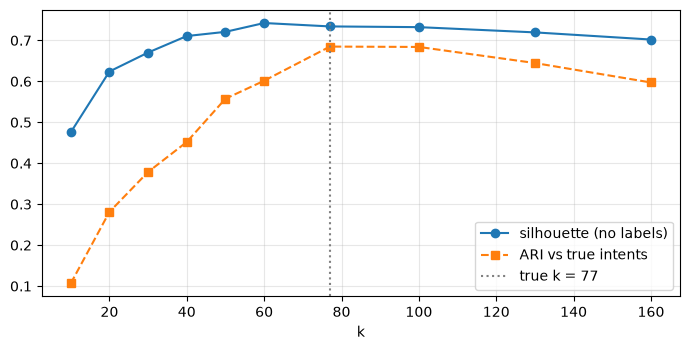

In [4]:
X = UMAP5[BEST]
SIL = {}
for k in [10, 20, 30, 40, 50, 60, 77, 100, 130, 160]:
    lab = KMeans(k, n_init=4, random_state=0).fit_predict(X)
    SIL[k] = (silhouette_score(X, lab), *score(lab))
    print(f"k={k:3d}: silhouette {SIL[k][0]:.3f} | ARI {SIL[k][1]:.3f} | NMI {SIL[k][2]:.3f}")
best_k = max(SIL, key=lambda k: SIL[k][0])
print(f"\nsilhouette picks k = {best_k}; the true number of intents is 77")

fig, ax = plt.subplots(figsize=(7, 3.6))
ks = list(SIL)
ax.plot(ks, [SIL[k][0] for k in ks], "o-", label="silhouette (no labels)")
ax.plot(ks, [SIL[k][1] for k in ks], "s--", label="ARI vs true intents")
ax.axvline(77, color="gray", ls=":", label="true k = 77"); ax.set_xlabel("k"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

**What the numbers say.** The silhouette score peaks at **k = 60**, not at the true 77. Its curve is flat between 50 and 100 (0.721–0.742), while ARI against the real intents keeps rising up to 77–100. That is the usual experience. Real text has no single "true" number of topics, because intents nest (card problems → card arrived damaged / card not working). Unsupervised scores can only rule out bad values of $k$: here, anything below about 40. In practice you pick a granularity that is useful for the decision at hand, look at the clusters, and merge or split by hand.

## 3. HDBSCAN: let the density decide

HDBSCAN on the 5-dimensional UMAP space, for several values of `min_cluster_size`. It returns the clusters it finds plus a noise label (−1). We report ARI on the clustered points and on all points (noise counted as one more "cluster"), the number of clusters and the share of noise.

min_cluster_size=10: 120 clusters | noise   6% | ARI clustered 0.651 (all 0.541) | NMI 0.873
min_cluster_size=15:  86 clusters | noise   5% | ARI clustered 0.696 (all 0.618) | NMI 0.881
min_cluster_size=20:  73 clusters | noise   5% | ARI clustered 0.683 (all 0.609) | NMI 0.881
min_cluster_size=30:  56 clusters | noise   5% | ARI clustered 0.614 (all 0.563) | NMI 0.866


min_cluster_size=40:  39 clusters | noise   7% | ARI clustered 0.465 (all 0.426) | NMI 0.825
using min_cluster_size=20: 73 clusters


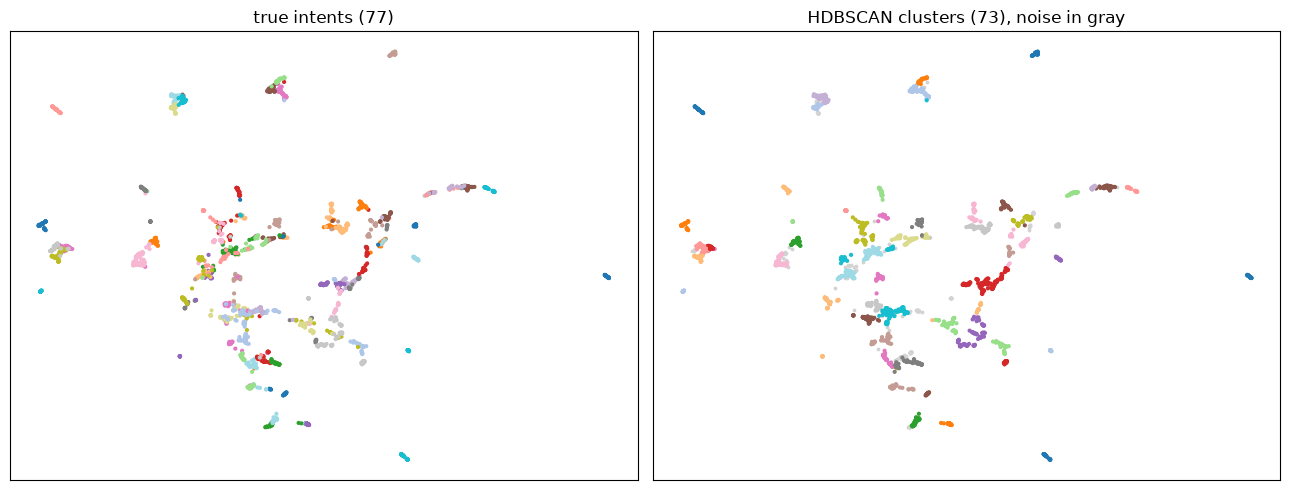

In [5]:
HDB = {}
for mcs in [10, 15, 20, 30, 40]:
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=5).fit_predict(UMAP5[BEST])
    keep = lab >= 0
    a_in, n_in = score(lab, keep); a_all, _ = score(lab)
    HDB[mcs] = lab
    print(f"min_cluster_size={mcs:2d}: {lab.max() + 1:3d} clusters | noise {np.mean(~keep):4.0%} | ARI clustered {a_in:.3f} (all {a_all:.3f}) | NMI {n_in:.3f}")
MCS = 20
labels = HDB[MCS]
n_clusters = labels.max() + 1
print(f"\nusing min_cluster_size={MCS}: {n_clusters} clusters")

coords = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(EMB[BEST])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(coords[:, 0], coords[:, 1], c=y, cmap="tab20", s=4); ax[0].set_title("true intents (77)")
ax[1].scatter(coords[labels < 0, 0], coords[labels < 0, 1], c="lightgray", s=3)
ax[1].scatter(coords[labels >= 0, 0], coords[labels >= 0, 1], c=labels[labels >= 0], cmap="tab20", s=4)
ax[1].set_title(f"HDBSCAN clusters ({n_clusters}), noise in gray")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**What the numbers say.**

- **Without being told $k$, HDBSCAN found 73 clusters with `min_cluster_size=20`**, close to the 77 intents. Their quality, ARI 0.683 on the clustered points, matches k-means *with* the true $k$ (0.685).
- **It set aside 5 % of the messages as noise**: ambiguous or one-off messages that no dense group claims. That is a feature. In production, the noise bucket is where odd requests, spam and new needs show up, instead of being forced into the nearest cluster.
- **`min_cluster_size` is the granularity knob**: 10 gives 120 small clusters, 40 gives 39 broad ones. The best ARI was at 15 (0.696, 86 clusters). The right value depends on the smallest topic you care about, not on a metric.
- In the 2-D picture the true intents form many compact islands, some touching. The clusters follow the islands, and the merges happen where islands touch.

## 4. Describing clusters: c-TF-IDF keywords and LLM names

c-TF-IDF from scratch: concatenate each cluster's messages, count words, weight each word's frequency in the cluster by $\log(1 + A / f_w)$, where $A$ is the average number of words per cluster and $f_w$ the word's total frequency across clusters. Then `qwen2.5:3b` names each cluster from its keywords and five example messages.

To check the names without reading 70 of them, we embed each LLM name and the 77 intent names, and test whether the nearest intent name is the cluster's majority intent.

In [6]:
cv = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
docs_per_cluster = [" ".join(t for t, l in zip(texts, labels) if l == c) for c in range(n_clusters)]
counts = cv.fit_transform(docs_per_cluster).toarray().astype(float)
tf = counts / counts.sum(1, keepdims=True)
idf = np.log(1 + counts.sum(1).mean() / counts.sum(0))
ctfidf = tf * idf
vocab = np.array(cv.get_feature_names_out())
KEYWORDS = [list(vocab[np.argsort(-row)[:6]]) for row in ctfidf]

from pydantic import BaseModel, Field
class TopicName(BaseModel):
    name: str = Field(description="a short name for what these customer messages are about, 2 to 6 words")
namer = get_llm(num_predict=40).with_structured_output(TopicName, method="json_schema")
rng = np.random.default_rng(0)
prompts = []
for c in range(n_clusters):
    ex = [texts[i] for i in rng.permutation(np.where(labels == c)[0])[:5]]
    prompts.append([("system", "You name clusters of customer messages sent to a bank."),
                    ("user", f"Keywords: {', '.join(KEYWORDS[c])}\nExamples:\n- " + "\n- ".join(ex))])
t0 = time.time()
NAMES = [r.name for r in namer.batch(prompts, config={"max_concurrency": 4})]
print(f"named {n_clusters} clusters in {time.time() - t0:.0f}s")

majority = [Counter(y[labels == c]).most_common(1)[0] for c in range(n_clusters)]
purity = np.array([cnt / np.sum(labels == c) for c, (_, cnt) in enumerate(majority)])
emb = SentenceTransformer("BAAI/bge-small-en-v1.5", device=device)
nearest = (emb.encode(NAMES, normalize_embeddings=True) @ emb.encode(INTENTS, normalize_embeddings=True).T).argmax(1)
name_ok = np.array([nearest[c] == majority[c][0] for c in range(n_clusters)])
print(f"cluster purity (share of the majority intent): median {np.median(purity):.0%} | the LLM name's nearest intent is the majority intent for "
      f"{name_ok.mean():.0%} of clusters ({name_ok.sum()} of {n_clusters})")
print(f"\n{'size':>4s}  {'purity':>6s}  {'LLM name':34s} {'c-TF-IDF keywords':42s} true majority intent")
for c in np.argsort(-np.bincount(labels[labels >= 0]))[:12]:
    print(f"{np.sum(labels == c):4d}  {purity[c]:6.0%}  {NAMES[c][:34]:34s} {', '.join(KEYWORDS[c][:4])[:42]:42s} {INTENTS[majority[c][0]]}")

named 73 clusters in 83s


cluster purity (share of the majority intent): median 91% | the LLM name's nearest intent is the majority intent for 58% of clusters (42 of 73)
size  purity  LLM name                           c-TF-IDF keywords                          true majority intent
 122     32%  Currency Exchange and Support Quer currencies, currency, support, exchange    fiat currency support
  71     51%  Transfer Requests Cluster          transfer money, money account, money, tran transfer into account
  64     59%  Transfer Issues Cluster            transfer, failed, message, error           failed transfer
  61     64%  Transfer Processing Time Requests  long, long does, transfer, china           transfer timing
  60     63%  Payment Decline Issues Cluster     declined, card declined, card payment, pay declined card payment
  60     63%  Card Acceptance Queries Cluster 1: use card, accepted, accept card, card use  card acceptance
  55     60%  Transfer Fee Concerns Cluster      transfer fee, fee, fee trans

**What the numbers say.**

- **Most clusters are clean**: the median cluster has 91 % of its messages from one intent.
- **The largest clusters are where intents merge.** The biggest, 122 messages, is only 32 % "fiat currency support": it merges several currency and exchange intents. The top 12 clusters have purities of 32–70 %. Size is a warning sign: a cluster much bigger than its neighbours usually needs splitting.
- **The keywords alone are already informative** ("declined, card declined, card payment" → declined card payment). c-TF-IDF needs no model and costs nothing.
- **The LLM's names match the cluster's majority intent for 58 % of clusters** (42 of 73), by the nearest-name test. Reading the table, many misses are names that are *right but broader* than the intent ("Transfer Issues Cluster" for failed transfer) or that describe a merged cluster accurately. The automatic test is strict. Naming took 83 s for 73 clusters with a 3B model.

A practical reading: c-TF-IDF tells you what a cluster contains, the LLM makes it readable, and a person still has to review the names before they become a taxonomy, an evaluation set or a routing table.

## 5. Monitoring: discovering intents nobody planned for

A deployed assistant knows a fixed set of intents, and users keep asking new things. We simulate it:
1. **Seven intents are held out as "unknown".** The assistant knows the other 70, through the centroid of each known intent's *training* messages.
2. **Flagging.** A test message whose highest cosine similarity to any known centroid falls below a threshold is flagged as *possibly new*. The threshold is set on known-intent messages only: the 5th percentile of their similarities.
3. **Clustering the flags.** The flagged messages are clustered with HDBSCAN, to see whether the unknown intents come out as clusters of their own.

In [7]:
rng = np.random.default_rng(1)
UNKNOWN = sorted(rng.choice(77, 7, replace=False).tolist())
known = [i for i in range(77) if i not in UNKNOWN]
tr_text, tr_y = bank["train"]["text"], np.array(bank["train"]["label"])
E_tr = emb.encode(tr_text, batch_size=128, normalize_embeddings=True)
centroids = np.stack([E_tr[tr_y == i].mean(0) for i in known]); centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
best_sim = (EMB[BEST] @ centroids.T).max(1)
is_new = np.isin(y, UNKNOWN)
thr = np.percentile(best_sim[~is_new], 5)
flag = best_sim < thr
print(f"unknown intents: {[INTENTS[i] for i in UNKNOWN]}")
print(f"threshold {thr:.3f} | flagged {flag.sum()} messages: {np.mean(is_new[flag]):.0%} of them really are from unknown intents "
      f"| recall: {np.mean(flag[is_new]):.0%} of the {is_new.sum()} unknown-intent messages flagged | false flags on known intents: {np.mean(flag[~is_new]):.0%}")

sub = np.where(flag)[0]
U = umap.UMAP(n_components=5, n_neighbors=10, min_dist=0.0, metric="cosine", random_state=0).fit_transform(EMB[BEST][sub])
lab_new = HDBSCAN(min_cluster_size=8, min_samples=3).fit_predict(U)
print(f"\nclusters among the flagged messages: {lab_new.max() + 1} (+ {np.mean(lab_new < 0):.0%} noise)")
for c in range(lab_new.max() + 1):
    members = sub[lab_new == c]
    top, cnt = Counter(y[members]).most_common(1)[0]
    status = "UNKNOWN intent" if top in UNKNOWN else "known intent"
    print(f"   cluster {c}: {len(members):3d} messages | {cnt / len(members):4.0%} {INTENTS[top]} ({status}) | e.g. {texts[members[0]][:70]!r}")
found = {Counter(y[sub[lab_new == c]]).most_common(1)[0][0] for c in range(lab_new.max() + 1)} & set(UNKNOWN)
print(f"\nunknown intents that surfaced as their own cluster: {len(found)} of {len(UNKNOWN)}: {[INTENTS[i] for i in sorted(found)]}")

unknown intents: ['apple pay or google pay', 'card acceptance', 'exchange via app', 'fiat currency support', 'terminate account', 'transaction charged twice', 'verify source of funds']
threshold 0.830 | flagged 297 messages: 53% of them really are from unknown intents | recall: 56% of the 280 unknown-intent messages flagged | false flags on known intents: 5%


clusters among the flagged messages: 16 (+ 5% noise)
   cluster 0:  31 messages |  52% fiat currency support (UNKNOWN intent) | e.g. 'Do you support all fiat currencies?'
   cluster 1:  13 messages |  85% verify source of funds (UNKNOWN intent) | e.g. 'Is a copy of the police report necessary for completing the report pro'
   cluster 2:  18 messages |  72% apple pay or google pay (UNKNOWN intent) | e.g. 'Do I need to make a regular payment before a contactless one?'
   cluster 3:   9 messages |  89% apple pay or google pay (UNKNOWN intent) | e.g. 'Can I be topped up once I hit a certain balance?'
   cluster 4:  12 messages |  75% exchange via app (UNKNOWN intent) | e.g. 'How do I change GBP to AUD?'
   cluster 5:  19 messages |  32% exchange via app (UNKNOWN intent) | e.g. 'Is it a good time to exchange?'
   cluster 6:  35 messages |  83% verify source of funds (UNKNOWN intent) | e.g. 'Is there tracking info available?'
   cluster 7:  10 messages |  30% pending card payment (known inte

**What the numbers say.**

- **The novelty flag is a coarse filter.** With a threshold at the 5th percentile of known-intent similarity (0.830), it flagged 297 messages. 53 % of them came from the 7 unknown intents, and it caught 56 % of their 280 messages. It also flagged 5 % of known-intent messages, by construction of the threshold. Many messages of a new intent look similar enough to a known one ("exchange via app" vs the known "exchange rate") to pass unflagged.
- **Clustering the flagged messages is what makes the signal readable.** HDBSCAN found 16 clusters among them, and **all 7 unknown intents came out as clusters where they are the majority**. Some came out several times: "terminate account" in three clusters. A few clusters were made of known intents near their boundary.

This is the monitoring loop teams run on production traffic:
1. flag what is far from what the system handles;
2. cluster it;
3. name the clusters;
4. have someone review the biggest ones each week.

The output becomes new intents for a router, new documents for a RAG index, or new cases for an evaluation set. Each cluster's example messages are what make the review fast.

## Results

| question | measured (Banking77 test, 3,080 messages, 77 intents) | lesson |
|---|---|---|
| which embedding | bge-small beats MiniLM: k-means ARI 0.685 vs 0.576 (on UMAP 5-d) | a better retrieval model clusters better too |
| UMAP before clustering | k-means ARI 0.581 → 0.685 (bge-small) | reduce to ~5 dimensions before clustering |
| choosing k without labels | silhouette picks 60 (true 77), flat between 50 and 100 | k is a granularity choice, not a discovery |
| HDBSCAN | 73 clusters found without k, ARI 0.683, 5 % noise | density clustering finds k and isolates the odd messages |
| describing clusters | median purity 91 %; LLM names match the majority intent in 58 % of clusters; biggest clusters merge intents | keywords + LLM names, then human review |
| emerging topics | flag precision 53 %, recall 56 %; all 7 unknown intents surfaced as clusters | flag, cluster, name, review: a weekly monitoring loop |

## In production

**The pipeline.**
- Embed with a model chosen for your domain (notebook 21), reduce with UMAP, cluster with HDBSCAN, describe with c-TF-IDF and an LLM.
- **BERTopic** packages exactly this, with topics over time, hierarchical topic merging and a choice of representation models. Use it instead of hand-rolled code unless you need control over a step.
- For millions of messages, use cuML's GPU UMAP and HDBSCAN, or cluster a sample and assign the rest to the nearest cluster centroid.

**Where it pays off.**
- **Understanding usage**: what users ask, how often, with examples. It is the first analysis on any new LLM product's logs.
- **Building evaluation sets**: sample from every cluster, so rare but important intents are represented (notebooks 10 and 15).
- **Finding failures**: cluster the conversations with negative feedback or failed tool calls, and fix the biggest cluster first.
- **Designing routers and intents** (notebooks 14 and 23) from data instead of guesses.
- **Monitoring**: flag messages far from known intents, cluster them weekly, review the new clusters.
- **Data work**: near-duplicate removal and diversity sampling for training data (notebook 18).

**What to watch.**
- Cluster sizes over time: a growing cluster is a growing need.
- The share of noise and of novelty flags.
- How stable the clusters are between runs: UMAP and HDBSCAN have random elements, so fix seeds, and compare runs by matching clusters rather than ids.

**Failure modes.**
- Trusting LLM-generated names without reading the examples.
- One giant cluster that hides several topics.
- Clustering on an embedding model that does not understand your domain (codes, jargon, other languages).
- Re-clustering from scratch every week, so cluster ids do not persist: assign new data to existing clusters and only re-cluster what does not fit.
- Personal data in the example messages shown on dashboards.

**Next:** `10_rag.ipynb`, where clusters of user questions become a representative evaluation set.